# Projeto Final - Aprendizado de Máquina 2024/1
## Sistema de Recomendação de Filmes

In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

import torch.nn as nn
import torch.optim as optim
import torch

## Processamento dos Dados e Geração de Matriz de Similaridade

In [2]:
## Data Loader Module
# Load data from files
class DataLoader:
    def __init__(self, ratings_file, content_file, targets_file):
        self.ratings_file = ratings_file
        self.content_file = content_file
        self.targets_file = targets_file

    def load_data(self):
        ratings = pd.read_json(self.ratings_file, lines=True)
        content = pd.read_json(self.content_file, lines=True)
        targets = pd.read_csv(self.targets_file)
        return ratings, content, targets

## Data Processor Module
# Generate tags from content data and generate similarity matrix from tags
class DataProcessor:
    def __init__(self, content, ratings):
        self.content = content
        self.ratings = ratings

    def filter_box_office(self, box_office):
        if box_office == 'N/A':
            return 'insignificante'

        if type(box_office) == str:
            cleaned_monetary_value = box_office.replace('$', '').replace(',', '')
            int_monetary_value = int(cleaned_monetary_value)
        else:
            int_monetary_value = box_office

        if int_monetary_value < 927821:
            return 'baixo'
        elif int_monetary_value < 17588670:
            return 'medio'
        else:
            return 'alto'
        
    def filter_year(self, year):
        try:
            year = int(year)
        except:
            return ''

        if year < 1900:
            return 'muito_antigo'
        elif year < 1950:
            return 'antigo'
        elif year < 1980:
            return 'quase_moderno'
        elif year < 1990:
            return 'moderno'
        elif year < 2000:
            return 'recente'
        elif year < 2010:
            return 'muito_recente'
        else:
            return 'atual'
        
    def check_oscar(self, string_awards):
        awards = string_awards.split()

        if 'Oscar.' in awards or 'Oscar' in awards:
            return 'Oscar'
        else:
            return ''

    # tags = genre + language + country + actors + year -> textual description of the movie
    def generate_tags(self):
        content_clear = self.content[['ItemId', 'Genre', 'Language', 'Country', 'imdbRating', 'imdbVotes', 'Year', 'Actors', 'Director', 'BoxOffice', 'Awards']].copy()
        content_clear['MovieId'] = content_clear['ItemId']
        content_clear = content_clear.set_index('MovieId')
        content_clear['newId'] = range(0, len(content_clear))

        content_clear['BoxOffice'] = content_clear['BoxOffice'].apply(self.filter_box_office)

        content_clear['Awards'] = content_clear['Awards'].apply(self.check_oscar)

        content_clear['Actors'] = content_clear['Actors'].apply(lambda x: x.replace(" ", ""))	
        content_clear['Actors'] = content_clear['Actors'].apply(lambda x: x.replace(",", " "))

        content_clear['Country'] = content_clear['Country'].apply(lambda x: x.replace(" ", ""))
        content_clear['Country'] = content_clear['Country'].apply(lambda x: x.replace(",", " "))
        
        content_clear['Director'] = content_clear['Director'].apply(lambda x: x.replace(" ", ""))
        content_clear['Director'] = content_clear['Director'].apply(lambda x: x.replace(",", " "))

        content_clear['Year'] = content_clear['Year'].apply(self.filter_year)

        content_clear['tags'] = content_clear['Genre'].str.replace('N/A', '') + ' ' + content_clear['Language'].str.replace('None', '') + ' ' + content_clear['Country'].str.replace('N/A', '') + ' ' + content_clear['Actors'].str.replace('N/A', '') + ' ' + content_clear['Year'] + content_clear['Director'].str.replace('N/A', '') + '' + content_clear['BoxOffice'] + '' + content_clear['Awards']

        content_clear['tags'] = content_clear['tags'].str.replace(',', '')

        self.content_clear = content_clear
        return content_clear

    # TF-IDF matrix to represent the textual description of the movie
    # Term Frequency-Inverse Document Frequency
    # Similarity between movies based on the TF-IDF matrix -> cosine similarity
    def generate_similarity_matrix(self):
        tfidf = TfidfVectorizer(stop_words='english', max_features=2000)  
        vectorized_data = tfidf.fit_transform(self.content_clear['tags'])
        svd = TruncatedSVD(n_components=100, random_state=42) 
        reduced_content_data = svd.fit_transform(vectorized_data)
        reduced_content_data = reduced_content_data.astype(np.float32)
        similarity_matrix = cosine_similarity(reduced_content_data)
        return similarity_matrix
    
    def map_ids(self):
        item_to_id = {}
        id_to_item = {}
        user_to_id = {}
        id_to_user = {}
        item_ids = []
        user_ids = []
        count = 0
        for item in self.ratings['ItemId']:
            if item not in item_to_id:
                item_to_id[item] = count
                id_to_item[count] = item
                count += 1
            item_ids.append(item_to_id[item])
        count = 0
        for user in self.ratings['UserId']:
            if user not in user_to_id:
                user_to_id[user] = count
                id_to_user[count] = user
                count += 1
            user_ids.append(user_to_id[user])

        return user_to_id, item_to_id, id_to_user, id_to_item, user_ids, item_ids

    def map_content(self):
        item_to_id = {}
        id_to_item = {}
        count = 0
        for item in self.content['ItemId']:
            if item not in item_to_id:
                item_to_id[item] = count
                id_to_item[count] = item
                count += 1
        
        return item_to_id, id_to_item

## Recomendador Manual e Recomendador PyTorch

In [3]:
## Recommender System Module
# Funk SVD to predict ratings of movies that already have ratings
# Content-based to predict ratings of movies that don't have ratings
class RecommenderSystem:
    def __init__(self, ratings, content_clear, similarity_matrix, targets, user_to_id, item_to_id, id_to_user, id_to_item, user_ids, item_ids, item_to_id_content):
        self.ratings = ratings
        self.content_clear = content_clear
        self.similarity_matrix = similarity_matrix
        self.targets = targets
        self.user_to_id = user_to_id
        self.item_to_id = item_to_id
        self.id_to_user = id_to_user
        self.id_to_item = id_to_item
        self.user_ids = user_ids
        self.item_ids = item_ids
        self.item_to_id_content = item_to_id_content
        self.user_preferences = None
        self.P = None
        self.Q = None
        self.bu = None
        self.bi = None
        self.mu = None

    # Mini-batch gradient descent to train the model
    def funkSvd(self):
        np.random.seed(42)

        self.ratings['UserId_num'] = self.user_ids
        self.ratings['ItemId_num'] = self.item_ids

        K = 20 # latent factors
        n_users = len(self.user_to_id)
        n_items = len(self.item_to_id)

        P = np.random.normal(scale=1./K, size=(n_users, K))
        Q = np.random.normal(scale=1./K, size=(n_items, K))
        bu = np.zeros(n_users)
        bi = np.zeros(n_items)
        mu = np.mean(self.ratings['Rating'])

        learning_rate = 0.01
        lambda_reg = 0.1 # regularization to avoid overfitting
        epochs = 15 # epochs
        batch_size = 256 

        num_batches = int(np.ceil(len(self.ratings) / float(batch_size)))

        for epoch in range(epochs):
            total_loss = 0 # total loss for the epoch
            
            indices = np.arange(len(self.ratings))
            np.random.shuffle(indices)

            for i in range(num_batches):
                # extracting the batch indices
                batch_indices = indices[i * batch_size: (i + 1) * batch_size]
                # extracting the batch from the dataframe
                batch = self.ratings.iloc[batch_indices] 
                users, items, true_ratings = batch['UserId_num'].values, batch['ItemId_num'].values, batch['Rating'].values
                
                preds = mu + bu[users] + bi[items] + np.sum(P[users, :] * Q[items, :], axis=1) # predicted ratings
                error = true_ratings - preds

                # loss calculation
                batch_loss = np.mean(error ** 2)
                total_loss += batch_loss

                # bias update
                bu[users] += learning_rate * (error - lambda_reg * bu[users])
                bi[items] += learning_rate * (error - lambda_reg * bi[items])
                
                # latent factors update
                for u, i, e in zip(users, items, error):
                    P[u, :] += learning_rate * (e * Q[i, :] - lambda_reg * P[u, :])
                    Q[i, :] += learning_rate * (e * P[u, :] - lambda_reg * Q[i, :])
            
            print(f'Epoch {epoch + 1}/{epochs}, Loss: {total_loss / num_batches}')
        
        self.P, self.Q, self.bu, self.bi, self.mu = P, Q, bu, bi, mu

    # Pytorch implementation of Funk SVD
    def funkSvdPytorch(self):
        np.random.seed(42)

        self.ratings['UserId_num'] = self.user_ids
        self.ratings['ItemId_num'] = self.item_ids

        K = 20 # latent factors
        n_users = len(self.user_to_id)
        n_items = len(self.item_to_id)

        user_ids = self.ratings['UserId_num'].values
        item_ids = self.ratings['ItemId_num'].values
        ratings_values = self.ratings['Rating'].values

        user_ids = torch.tensor(user_ids, dtype=torch.long)
        item_ids = torch.tensor(item_ids, dtype=torch.long)
        ratings_values = torch.tensor(ratings_values, dtype=torch.float)

        class MatrixFactorization(nn.Module):
            def __init__(self, num_users, num_items, emb_size):
                super(MatrixFactorization, self).__init__()
                self.user_emb = nn.Embedding(num_users, emb_size)
                self.item_emb = nn.Embedding(num_items, emb_size)

            def forward(self, user, item):
                user_emb = self.user_emb(user)
                item_emb = self.item_emb(item)
                return (user_emb * item_emb).sum(1)

        model = MatrixFactorization(n_users, n_items, K)
        loss_fn = nn.MSELoss()
        optimizer = optim.Adam(model.parameters(), lr=0.01)

        epochs = 15
        batch_size = 256

        for epoch in range(epochs):
            model.train()
            total_loss = 0
            num_batches = int(np.ceil(len(self.ratings) / float(batch_size)))
            indices = np.arange(len(self.ratings))
            np.random.shuffle(indices)

            for i in range(num_batches):
                batch_indices = indices[i * batch_size: (i + 1) * batch_size]
                user_batch = user_ids[batch_indices]
                item_batch = item_ids[batch_indices]
                rating_batch = ratings_values[batch_indices]

                optimizer.zero_grad()
                output = model(user_batch, item_batch)
                loss = loss_fn(output, rating_batch)
                loss.backward()
                optimizer.step()
                total_loss += loss.item()

            print(f'Epoch {epoch+1}/{epochs}, Loss: {total_loss/num_batches}')

        self.P = model.user_emb.weight.detach().numpy()
        self.Q = model.item_emb.weight.detach().numpy()
        self.bu = np.zeros(n_users)
        self.bi = np.zeros(n_items)
        self.mu = np.mean(self.ratings['Rating'])
    
    def item_id_to_sim_index(self, item_id):
        if item_id in self.content_clear.index:
            return self.content_clear.loc[item_id, 'newId']
        else:
            return None
        
    # Calculate user preferences based on the ratings of the movies that the user has already rated (top 15)
    def calculate_user_preferences(self, unique_users_in_targets):
        user_preferences = {}

        for user_id in unique_users_in_targets:
            user_ratings = self.ratings[self.ratings['UserId'] == user_id].nlargest(15, 'Rating')
            idxs = [self.item_id_to_sim_index(item_id) for item_id in user_ratings['ItemId'].values]

            total_similarity = np.sum(self.similarity_matrix[idxs] * user_ratings['Rating'].values[:, np.newaxis], axis=0)
            total_weights = np.sum(user_ratings['Rating'].values)

            user_pref = total_similarity / total_weights if total_weights != 0 else np.zeros(self.similarity_matrix.shape[1])

            user_preferences[user_id] = user_pref

        self.user_preferences = user_preferences
        return user_preferences
    
    # Content-based to predict ratings of movies that don't have ratings
    def content_based(self, item_id_str, user_id_str, mu):
        user_pref = self.user_preferences.get(user_id_str, np.zeros(self.similarity_matrix.shape[1]))
        item_idx = self.item_id_to_sim_index(item_id_str)

        if item_idx is None:
            return mu
        
        top_n = 40 # top 40 similar movies to the movie that we want to predict the rating
        top_indices = np.argsort(-user_pref)[:top_n]

        # Score is the dot product of the user preferences and the similarity matrix
        score = np.dot(user_pref[top_indices], self.similarity_matrix[item_idx, top_indices])

        # Normalize the score
        min_score, max_score = 0, 10
        score = (score - min_score) / (max_score - min_score) * 9 + 1

        return score

    # Predict ratings based on the Funk SVD model and the content-based model
    def predict(self, user_id_str, item_id_str, imdbRatings, imdbVotes):
        if item_id_str not in self.item_to_id:
            calculated_rating = self.content_based(item_id_str, user_id_str, self.mu)
        else:
            user_id = self.user_to_id[user_id_str]
            item_id = self.item_to_id[item_id_str]

            calculated_rating = np.clip(self.mu + self.bu[user_id] + self.bi[item_id] + np.dot(self.P[user_id, :], self.Q[item_id, :]), 1, 10)
        
        imdb_rating_movie = imdbRatings[self.item_to_id_content[item_id_str]]
        imdb_votes_movie = imdbVotes[self.item_to_id_content[item_id_str]]

        # Uses the IMDB rating and the number of votes to calculate the final rating
        return calculated_rating * (imdb_rating_movie / 10) * (imdb_votes_movie / 1000000)
    
    # Re-order the movies based on the predicted ratings
    def order_predictions(self, items_per_user, imdbRatings, imdbVotes):
        ordered_predictions = {}

        for user, items in items_per_user.items():
            items_with_predictions = [(item, self.predict(user, item, imdbRatings, imdbVotes)) for item in items]

            ordered_items = sorted(items_with_predictions, key=lambda x: x[1], reverse=True)

            ordered_predictions[user] = ordered_items

        return ordered_predictions
    
    def print_result(self, ordered_predictions, filename):
        print('Writing results to file ', filename)
        results = []

        for user, items in ordered_predictions.items():
            for item, _ in items:
                results.append((user, item))

        df_results = pd.DataFrame(results, columns=['UserId', 'ItemId'])
        df_results.to_csv(filename, index=False)

## Carregamento dos Dados

In [4]:
args = ['ratings.jsonl', 'content.jsonl', 'targets.csv']
data_loader = DataLoader(args[0], args[1], args[2])
ratings, content, targets = data_loader.load_data()

data_processor = DataProcessor(content, ratings)
content_clear = data_processor.generate_tags()
similarity_matrix = data_processor.generate_similarity_matrix()

In [5]:
user_to_id, item_to_id, id_to_user, id_to_item, user_ids, item_ids = data_processor.map_ids()
item_to_id_content, id_to_item_content = data_processor.map_content()

In [6]:
content['imdbRating'] = pd.to_numeric(content['imdbRating'], errors='coerce').fillna(1)
content['imdbVotes'] = content['imdbVotes'].str.replace(',', '')
content['imdbVotes'] = pd.to_numeric(content['imdbVotes'], errors='coerce').fillna(1)
imdbRatings = content['imdbRating'].to_numpy()
imdbVotes = content['imdbVotes'].to_numpy()

unique_users_in_targets = targets['UserId'].unique()
items_per_user = targets.groupby('UserId')['ItemId'].apply(list)

## Chamada dos Recomendadores e Análise da Perda por Época

In [7]:
# Manual Recommender
manual_recommender = RecommenderSystem(ratings, content_clear, similarity_matrix, targets, user_to_id, item_to_id, id_to_user, id_to_item, user_ids, item_ids, item_to_id_content)
manual_recommender.funkSvd()
global_user_preferences = manual_recommender.calculate_user_preferences(unique_users_in_targets)
ordered_predictions_manual = manual_recommender.order_predictions(items_per_user, imdbRatings, imdbVotes)
manual_recommender.print_result(ordered_predictions_manual, 'manual_recommender_results.csv')

Epoch 1/15, Loss: 2.666737480677712
Epoch 2/15, Loss: 2.3230765518933203
Epoch 3/15, Loss: 2.2165028594144522
Epoch 4/15, Loss: 2.154703710745149
Epoch 5/15, Loss: 2.1040543114887416
Epoch 6/15, Loss: 2.062628154955575
Epoch 7/15, Loss: 2.02107756270087
Epoch 8/15, Loss: 1.9750342607981148
Epoch 9/15, Loss: 1.9243250725868633
Epoch 10/15, Loss: 1.8709586788185855
Epoch 11/15, Loss: 1.8165932591164111
Epoch 12/15, Loss: 1.7610140573183026
Epoch 13/15, Loss: 1.7052983009494669
Epoch 14/15, Loss: 1.6507888151762005
Epoch 15/15, Loss: 1.595491801342612
Writing results to file  manual_recommender_results.csv


In [8]:
global_user_preferences = manual_recommender.user_preferences

In [9]:
# PyTorch Recommender
pytorch_recommender = RecommenderSystem(ratings, content_clear, similarity_matrix, targets, user_to_id, item_to_id, id_to_user, id_to_item, user_ids, item_ids, item_to_id_content)
pytorch_recommender.funkSvdPytorch()
pytorch_recommender.user_preferences = global_user_preferences
ordered_predictions_pytorch = pytorch_recommender.order_predictions(items_per_user, imdbRatings, imdbVotes)
pytorch_recommender.print_result(ordered_predictions_pytorch, 'pytorch_recommender_results.csv')

Epoch 1/15, Loss: 51.72616978834728
Epoch 2/15, Loss: 8.57392661251515
Epoch 3/15, Loss: 3.8232291751910403
Epoch 4/15, Loss: 3.087165044203019
Epoch 5/15, Loss: 2.9313191889421804
Epoch 6/15, Loss: 2.703871055986643
Epoch 7/15, Loss: 2.552725753921053
Epoch 8/15, Loss: 2.4517671101957075
Epoch 9/15, Loss: 2.355893940450241
Epoch 10/15, Loss: 2.284779808704385
Epoch 11/15, Loss: 2.221996514301507
Epoch 12/15, Loss: 2.1672910773726377
Epoch 13/15, Loss: 2.1178706026151257
Epoch 14/15, Loss: 2.0782356925765333
Epoch 15/15, Loss: 2.0427322226314235
Writing results to file  pytorch_recommender_results.csv


## Análise dos Resultados

Mean of normalized importances (Manual Recommender): 0.4628108114039315
Mean of normalized importances (PyTorch Recommender): 0.46307219178766995
Mean of normalized importances (IMDb Votes): 0.4629456919110721
Mean of normalized importances (IMDb Rating): 0.38998841452628696


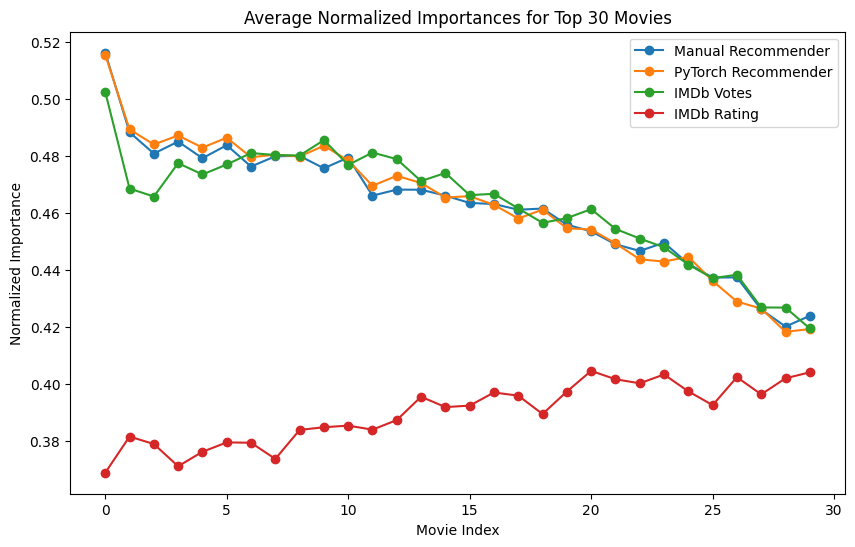

In [11]:
import matplotlib.pyplot as plt

# Calculates the importance of each movie for a user
def calculate_importance(user_preferences, similarity_matrix, user_id_str, item_ids, item_id_to_sim_index):
    user_pref = user_preferences.get(user_id_str, np.zeros(similarity_matrix.shape[1]))
    importances = []
    for item_id_str in item_ids:
        item_idx = item_id_to_sim_index(item_id_str)
        if item_idx is not None:
            importance = np.dot(user_pref, similarity_matrix[item_idx])
        else:
            importance = 0
        importances.append(importance)
    return np.array(importances)

# Normalizes the importances in order to compare them
def normalize_importances(importances):
    min_importance = np.min(importances)
    max_importance = np.max(importances)
    normalized_importances = (importances - min_importance) / (max_importance - min_importance)
    return normalized_importances

# Plots the normalized importances for the top 30 movies
def plot_importances(normalized_importances_list, labels):
    plt.figure(figsize=(10, 6))
    for normalized_importances, label in zip(normalized_importances_list, labels):
        plt.plot(normalized_importances, marker='o', label=label)
    plt.title('Average Normalized Importances for Top 30 Movies')
    plt.xlabel('Movie Index')
    plt.ylabel('Normalized Importance')
    plt.legend()
    plt.show()

# Analyzes the importances for the top 30 movies for both recommenders
def analyze_importances(sub, recommender_system, method_label):
    unique_users_in_sub = sub['UserId'].unique()
    all_normalized_importances = []

    for user_id in unique_users_in_sub:
        item_ids = sub[sub['UserId'] == user_id]['ItemId'].values[:30]
        importances = calculate_importance(recommender_system.user_preferences, recommender_system.similarity_matrix, user_id, item_ids, recommender_system.item_id_to_sim_index)
        normalized_importances = normalize_importances(importances)
        all_normalized_importances.append(normalized_importances)

    mean_normalized_importances = np.mean(all_normalized_importances, axis=0)
    mean = np.mean(mean_normalized_importances)
    print(f'Mean of normalized importances ({method_label}): {mean}')
    return mean_normalized_importances

# Gets the top 20 movies for each user based on a metric (imdbVotes or imdbRating)
def get_top_20_movies_by_metric(targets, content, metric, metric_name):
    targets = targets.merge(content[['ItemId', metric]], on='ItemId', how='left')
    targets[metric] = targets[metric].fillna(content[metric].mean())
    
    top_20_movies_by_user = {}
    grouped = targets.groupby('UserId')
    for user_id, group in grouped:
        sorted_group = group.sort_values(by=metric, ascending=False)
        top_20_movies = sorted_group['ItemId'].values[:30]
        top_20_movies_by_user[user_id] = top_20_movies
    return top_20_movies_by_user

# Analyzes the importances for the top 30 movies for imdbVotes and imdbRating metrics
def analyze_importances_by_metric(targets, content, metric, recommender_system, method_label):
    top_20_movies_by_user = get_top_20_movies_by_metric(targets, content, metric, method_label)
    all_normalized_importances = []

    for user_id in top_20_movies_by_user:
        if user_id not in recommender_system.user_preferences:
            continue
        item_ids = top_20_movies_by_user[user_id]
        importances = calculate_importance(recommender_system.user_preferences, recommender_system.similarity_matrix, user_id, item_ids, recommender_system.item_id_to_sim_index)
        normalized_importances = normalize_importances(importances)
        all_normalized_importances.append(normalized_importances)

    mean_normalized_importances = np.mean(all_normalized_importances, axis=0)
    mean = np.mean(mean_normalized_importances)
    print(f'Mean of normalized importances ({method_label}): {mean}')
    return mean_normalized_importances

# Execute the analysis and plot the results
manual_results = pd.read_csv('manual_recommender_results.csv')
pytorch_results = pd.read_csv('pytorch_recommender_results.csv')

mean_normalized_importances_manual = analyze_importances(manual_results, manual_recommender, 'Manual Recommender')
mean_normalized_importances_pytorch = analyze_importances(pytorch_results, pytorch_recommender, 'PyTorch Recommender')

mean_normalized_importances_imdb_votes = analyze_importances_by_metric(targets, content, 'imdbVotes', manual_recommender, 'IMDb Votes')
mean_normalized_importances_imdb_rating = analyze_importances_by_metric(targets, content, 'imdbRating', manual_recommender, 'IMDb Rating')

# Plot all the results together for comparison
plot_importances(
    [
        mean_normalized_importances_manual,
        mean_normalized_importances_pytorch,
        mean_normalized_importances_imdb_votes,
        mean_normalized_importances_imdb_rating
    ],
    ['Manual Recommender', 'PyTorch Recommender', 'IMDb Votes', 'IMDb Rating']
)